# Compact Sequential Discrimination Algorithm Comparison

This notebook compares exhaustive optimal allocation, greedy allocation, heuristic allocation, uniform allocation, and a random allocation-tree baseline on exactly the same cases and sensor budgets. It focuses on two research questions:

1. How much final error is added by each approximate method?
2. How much computation time does each method save relative to exhaustive search?

The default test uses 10 realizations from every field-family, $K$, and $M$ cell in both the 1D and 2D compact benchmarks, giving 180 cases per dataset.

In [1]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Find the module folder when the notebook starts from the repository root or this folder.
working_directory = Path.cwd().resolve()
MODULE_DIRECTORY = (
    working_directory / "min-error-sequential"
    if (working_directory / "min-error-sequential").is_dir()
    else working_directory
)
# Add the local module folder so the analysis code can be imported below.
if str(MODULE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(MODULE_DIRECTORY))

# Reload local analysis code when this notebook is already open.
import comparison_analysis
comparison_analysis = importlib.reload(comparison_analysis)
field_family_summary = comparison_analysis.field_family_summary
load_paired_results = comparison_analysis.load_paired_results
overall_error_curve_summary = comparison_analysis.overall_error_curve_summary
paired_summary = comparison_analysis.paired_summary
runtime_by_k_summary = comparison_analysis.runtime_by_k_summary
run_paired_dataset = comparison_analysis.run_paired_dataset

## Run settings

The test uses 10 replicates from each of the 18 field-family, $K$, and $M$ cells, giving 180 cases per dataset. Set `RUN_ALL_REPLICATES = True` to use all 2,520 cases in each dimension. The full run takes much longer because every case also runs exhaustive search.

In [2]:
# Run both spatial benchmark datasets. Each dataset contains 2,520 cases.
DATASETS = ["compact_benchmark_1d", "compact_benchmark_2d"]

# False runs 180 test cases. True runs all 2,520 cases in each dataset.
RUN_ALL_REPLICATES = True

# None keeps every replicate; 10 gives 180 balanced test cases.
REPLICATES_PER_CELL = None if RUN_ALL_REPLICATES else 10
RUN_SCOPE = "full" if RUN_ALL_REPLICATES else "test"

# Save result tables and figures under this directory.
RESULTS_ROOT = MODULE_DIRECTORY / "results" / "algorithm_comparison_compact"

print("Run mode:", "all 2,520 cases" if RUN_ALL_REPLICATES else "test: 10 replicates per cell (180 cases)")
print("Results directory:", RESULTS_ROOT)

Run mode: all 2,520 cases
Results directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/algorithm_comparison_compact


## Algorithm configuration

Each dictionary is passed only to its matching algorithm. `improvement_threshold` is the minimum absolute reduction in final tree error required to accept a one-sensor move. The heuristic stops when no move exceeds this threshold or when `max_iterations` is reached.

In [3]:
# Exhaustive search has no optional tuning parameters.
OPTIMAL_PARAMETERS = {}

# The existing greedy method has no optional tuning parameters.
GREEDY_PARAMETERS = {}

# Configure tree construction, allocation moves, and initialization.
TREE_AWARE_PARAMETERS = {
    "beam_width": 3,  # Number of partial trees kept after each expansion.
    "max_iterations": 25,  # Maximum allocation-search iterations.
    "improvement_threshold": 1e-3,  # Required reduction in final error.
    "initialization": "near_uniform",  # Use "random" for a fully random start.
    "random_seed": 0,  # Reproduces the start and random move order.
}

# Use the same seed as the heuristic's near-uniform starting allocation.
UNIFORM_PARAMETERS = {
    "random_seed": 0,
}

# Reproduce case-specific random allocations and decision trees.
RANDOM_PARAMETERS = {
    "random_seed": 0,
}

print("Optimal parameters:", OPTIMAL_PARAMETERS)
print("Greedy parameters:", GREEDY_PARAMETERS)
print("Heuristic parameters:", TREE_AWARE_PARAMETERS)
print("Uniform parameters:", UNIFORM_PARAMETERS)
print("Random parameters:", RANDOM_PARAMETERS)

Optimal parameters: {}
Greedy parameters: {}
Heuristic parameters: {'beam_width': 3, 'max_iterations': 25, 'improvement_threshold': 0.001, 'initialization': 'near_uniform', 'random_seed': 0}
Uniform parameters: {'random_seed': 0}
Random parameters: {'random_seed': 0}


## Run all five algorithms

Each record is paired: Optimal, Greedy, Heuristic, Uniform, and Random receive the same $K$, $M$, budget, phase gaps, and sparse $P_{ijmn}$ values.

In [4]:
# Keep each dimension separate so the plots can show 1D and 2D side by side.
records_by_dataset = {}
for dataset in DATASETS:
    display(Markdown(f"### Running `{dataset}`"))
    # Run all algorithms using the same cases and budgets.
    records_by_dataset[dataset] = run_paired_dataset(
        dataset,  # Name of the input benchmark directory.
        replicates_per_cell=REPLICATES_PER_CELL,  # None means all cases.
        results_root=RESULTS_ROOT,  # Base directory for comparison results.
        optimal_parameters=OPTIMAL_PARAMETERS,
        greedy_parameters=GREEDY_PARAMETERS,
        tree_aware_parameters=TREE_AWARE_PARAMETERS,
        uniform_parameters=UNIFORM_PARAMETERS,
        random_parameters=RANDOM_PARAMETERS,
    )

### Running `compact_benchmark_1d`

compact_benchmark_1d: completed case 1/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 2/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 3/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 4/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 5/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 6/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 7/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 8/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 9/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 10/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 11/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 12/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 13/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 14/2520 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 15/2520 (gaussian, K=3, M=3)
compact_benchmark_1

### Running `compact_benchmark_2d`

compact_benchmark_2d: completed case 1/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 2/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 3/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 4/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 5/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 6/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 7/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 8/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 9/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 10/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 11/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 12/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 13/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 14/2520 (gaussian, K=3, M=3)
compact_benchmark_2d: completed case 15/2520 (gaussian, K=3, M=3)
compact_benchmark_2

## Paired comparison summary

In [5]:
# Start a Markdown table for the main quality and runtime statistics.
summary_lines = [
    "| Dataset | Method | Cases | Paired runs | Mean error gap | Maximum gap | Exact-error matches | Median speedup |",
    "|---|---|---:|---:|---:|---:|---:|---:|",
]
for dataset, records in records_by_dataset.items():
    # Calculate statistics from paired runs within one spatial dimension.
    summary = paired_summary(records)
    # The prefix selects the matching values from the summary dictionary.
    for method, prefix in (
        ("Greedy", "greedy"),
        ("Heuristic", "tree_aware"),
        ("Uniform", "uniform"),
        ("Random", "random"),
    ):
        summary_lines.append(
            f"| {dataset} | {method} | {summary['cases']} | {summary['runs']} | "
            f"{summary[f'{prefix}_mean_gap']:.4f} | "
            f"{summary[f'{prefix}_maximum_gap']:.4f} | "
            f"{100 * summary[f'{prefix}_exact_match_rate']:.1f}% | "
            f"{summary[f'{prefix}_median_speedup']:.1f}x |"
        )
# Render the completed table inside the notebook.
display(Markdown("\n".join(summary_lines)))

| Dataset | Method | Cases | Paired runs | Mean error gap | Maximum gap | Exact-error matches | Median speedup |
|---|---|---:|---:|---:|---:|---:|---:|
| compact_benchmark_1d | Greedy | 2520 | 9996 | 0.1124 | 0.5892 | 10.9% | 22.2x |
| compact_benchmark_1d | Heuristic | 2520 | 9996 | 0.0836 | 0.4830 | 17.3% | 11.9x |
| compact_benchmark_1d | Uniform | 2520 | 9996 | 0.2522 | 0.6086 | 0.6% | 283.4x |
| compact_benchmark_1d | Random | 2520 | 9996 | 0.2363 | 0.6734 | 0.5% | 277.0x |
| compact_benchmark_2d | Greedy | 2520 | 10019 | 0.1146 | 0.6608 | 10.7% | 22.3x |
| compact_benchmark_2d | Heuristic | 2520 | 10019 | 0.0866 | 0.5090 | 17.3% | 12.2x |
| compact_benchmark_2d | Uniform | 2520 | 10019 | 0.2478 | 0.6408 | 0.4% | 290.9x |
| compact_benchmark_2d | Random | 2520 | 10019 | 0.2337 | 0.6644 | 0.4% | 286.5x |

## Overall error-curve summary

Each row matches one point in the overall mean-error curves. Gap cells show the absolute error reduction followed by the percentage reduction relative to the first method; positive values mean the second method is better.

In [6]:
curve_summary_lines = [
    r"| Dimension | Budget level | Mean $N/N_{\min}$ | Optimal mean error | Greedy mean error | Heuristic mean error | Uniform mean error | Random mean error | Optimal reduction from Greedy | Optimal reduction from Heuristic | Heuristic reduction from Greedy |",
    "|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in overall_error_curve_summary(records):
        curve_summary_lines.append(
            f"| {row['dimension']} | {row['budget_level']} | "
            f"{row['mean_budget_fraction']:.3f} | "
            f"{row['optimal_mean_error']:.4f} | "
            f"{row['greedy_mean_error']:.4f} | "
            f"{row['heuristic_mean_error']:.4f} | "
            f"{row['uniform_mean_error']:.4f} | "
            f"{row['random_mean_error']:.4f} | "
            f"{row['optimal_from_greedy']:.4f} "
            f"({row['optimal_from_greedy_percent']:.1f}%) | "
            f"{row['optimal_from_heuristic']:.4f} "
            f"({row['optimal_from_heuristic_percent']:.1f}%) | "
            f"{row['heuristic_from_greedy']:.4f} "
            f"({row['heuristic_from_greedy_percent']:.1f}%) |"
        )
display(Markdown("\n".join(curve_summary_lines)))

| Dimension | Budget level | Mean $N/N_{\min}$ | Optimal mean error | Greedy mean error | Heuristic mean error | Uniform mean error | Random mean error | Optimal reduction from Greedy | Optimal reduction from Heuristic | Heuristic reduction from Greedy |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 1D | 1 | 0.179 | 0.4212 | 0.5023 | 0.4685 | 0.6170 | 0.6000 | 0.0811 (16.1%) | 0.0473 (10.1%) | 0.0338 (6.7%) |
| 1D | 2 | 0.334 | 0.2311 | 0.3542 | 0.3117 | 0.5089 | 0.4848 | 0.1231 (34.8%) | 0.0806 (25.9%) | 0.0425 (12.0%) |
| 1D | 3 | 0.499 | 0.1179 | 0.2463 | 0.2194 | 0.3982 | 0.3825 | 0.1283 (52.1%) | 0.1015 (46.3%) | 0.0269 (10.9%) |
| 1D | 4 | 0.634 | 0.0687 | 0.1860 | 0.1747 | 0.3237 | 0.3174 | 0.1173 (63.1%) | 0.1059 (60.6%) | 0.0114 (6.1%) |
| 2D | 1 | 0.162 | 0.4540 | 0.5276 | 0.4978 | 0.6340 | 0.6177 | 0.0736 (14.0%) | 0.0438 (8.8%) | 0.0298 (5.6%) |
| 2D | 2 | 0.302 | 0.2723 | 0.3915 | 0.3533 | 0.5402 | 0.5183 | 0.1191 (30.4%) | 0.0809 (22.9%) | 0.0382 (9.8%) |
| 2D | 3 | 0.452 | 0.1587 | 0.2927 | 0.2647 | 0.4366 | 0.4252 | 0.1340 (45.8%) | 0.1060 (40.0%) | 0.0280 (9.6%) |
| 2D | 4 | 0.573 | 0.1031 | 0.2352 | 0.2196 | 0.3690 | 0.3623 | 0.1320 (56.1%) | 0.1165 (53.0%) | 0.0155 (6.6%) |

## Runtime summary by number of fields

Each cell reports median runtime followed by median speedup relative to exhaustive Optimal search. Optimal is the 1x reference.

In [7]:
runtime_summary_lines = [
    "| Dimension | $K$ | Optimal median runtime (s) | Greedy runtime (speedup) | Heuristic runtime (speedup) | Uniform runtime (speedup) | Random runtime (speedup) |",
    "|---|---:|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in runtime_by_k_summary(records):
        runtime_summary_lines.append(
            f"| {row['dimension']} | {row['K']} | "
            f"{row['optimal_median_seconds']:.6f} | "
            f"{row['greedy_median_seconds']:.6f} "
            f"({row['greedy_median_speedup']:.1f}x) | "
            f"{row['heuristic_median_seconds']:.6f} "
            f"({row['heuristic_median_speedup']:.1f}x) | "
            f"{row['uniform_median_seconds']:.6f} "
            f"({row['uniform_median_speedup']:.1f}x) | "
            f"{row['random_median_seconds']:.6f} "
            f"({row['random_median_speedup']:.1f}x) |"
        )
display(Markdown("\n".join(runtime_summary_lines)))

| Dimension | $K$ | Optimal median runtime (s) | Greedy runtime (speedup) | Heuristic runtime (speedup) | Uniform runtime (speedup) | Random runtime (speedup) |
|---|---:|---:|---:|---:|---:|---:|
| 1D | 3 | 0.001513 | 0.000461 (3.3x) | 0.000648 (2.3x) | 0.000071 (23.3x) | 0.000071 (22.8x) |
| 1D | 4 | 0.021326 | 0.001008 (22.0x) | 0.002271 (9.1x) | 0.000119 (256.0x) | 0.000119 (253.1x) |
| 1D | 5 | 0.564408 | 0.002133 (226.2x) | 0.009837 (53.8x) | 0.000205 (3398.0x) | 0.000206 (3352.3x) |
| 2D | 3 | 0.000779 | 0.000239 (3.3x) | 0.000328 (2.4x) | 0.000036 (23.5x) | 0.000036 (23.0x) |
| 2D | 4 | 0.017028 | 0.000625 (22.2x) | 0.001441 (9.1x) | 0.000066 (261.3x) | 0.000065 (262.9x) |
| 2D | 5 | 0.357323 | 0.001521 (225.3x) | 0.006818 (51.6x) | 0.000115 (3401.8x) | 0.000114 (3368.9x) |

## Error-gap summary by field family

Each row averages the gap above Optimal over all included $K$, $M$, sensor budgets, and replicates. The final column reports how much the Heuristic reduces the Greedy gap.

In [8]:
family_summary_lines = [
    "| Dimension | Field family | Greedy mean gap | Heuristic mean gap | Uniform mean gap | Random mean gap | Heuristic gap reduction from Greedy |",
    "|---|---|---:|---:|---:|---:|---:|",
]
for records in records_by_dataset.values():
    for row in field_family_summary(records):
        family_summary_lines.append(
            f"| {row['dimension']} | {row['field_family']} | "
            f"{row['greedy_mean_gap']:.4f} | "
            f"{row['heuristic_mean_gap']:.4f} | "
            f"{row['uniform_mean_gap']:.4f} | "
            f"{row['random_mean_gap']:.4f} | "
            f"{row['heuristic_gap_reduction']:.4f} "
            f"({row['heuristic_gap_reduction_percent']:.1f}%) |"
        )
display(Markdown("\n".join(family_summary_lines)))

| Dimension | Field family | Greedy mean gap | Heuristic mean gap | Uniform mean gap | Random mean gap | Heuristic gap reduction from Greedy |
|---|---|---:|---:|---:|---:|---:|
| 1D | gaussian | 0.1291 | 0.0908 | 0.2598 | 0.2504 | 0.0383 (29.7%) |
| 1D | sinusoidal | 0.0787 | 0.0539 | 0.2245 | 0.2113 | 0.0247 (31.4%) |
| 1D | quadratic | 0.1286 | 0.1054 | 0.2716 | 0.2467 | 0.0232 (18.0%) |
| 2D | gaussian | 0.1389 | 0.1007 | 0.2503 | 0.2445 | 0.0382 (27.5%) |
| 2D | sinusoidal | 0.0725 | 0.0504 | 0.2224 | 0.2105 | 0.0221 (30.5%) |
| 2D | quadratic | 0.1316 | 0.1082 | 0.2703 | 0.2456 | 0.0234 (17.8%) |

## Comparison plots

1. **Mean error curves:** shows the quality-budget tradeoff separately for each $K$ using solid lines.
2. **Overall mean error curves:** summarizes 1D and 2D after averaging across all included $K$, $M$, and field families.
3. **Runtime speedup:** shows the computational benefit relative to exhaustive search.
4. **Error gap by field family:** compares Gaussian, sinusoidal, and quadratic fields in that order.

## Mean error curves

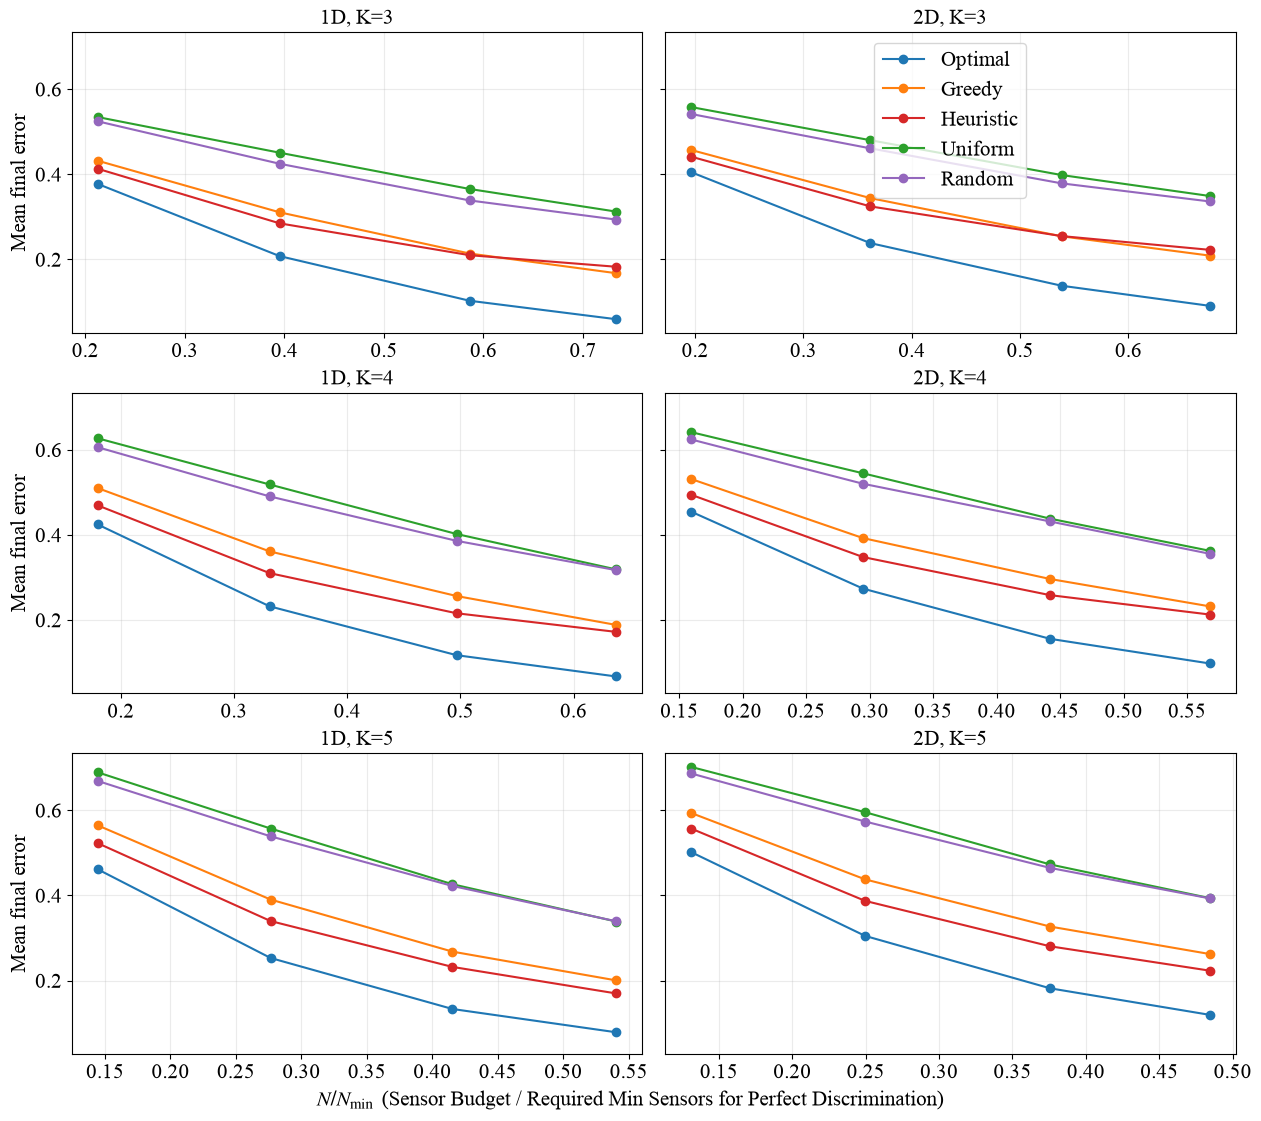

## Overall mean error curves

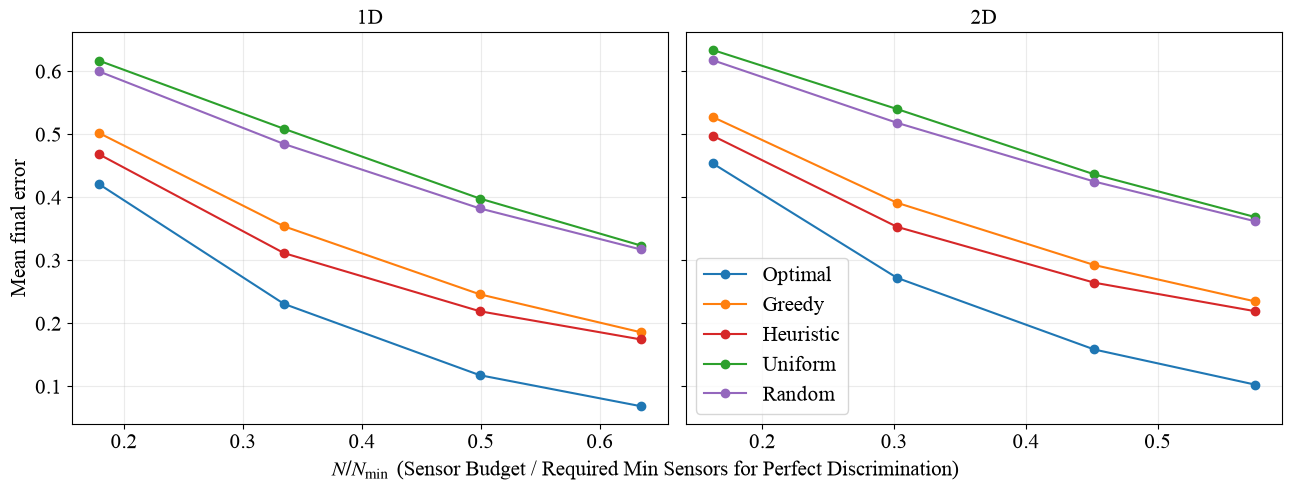

## Runtime speedup

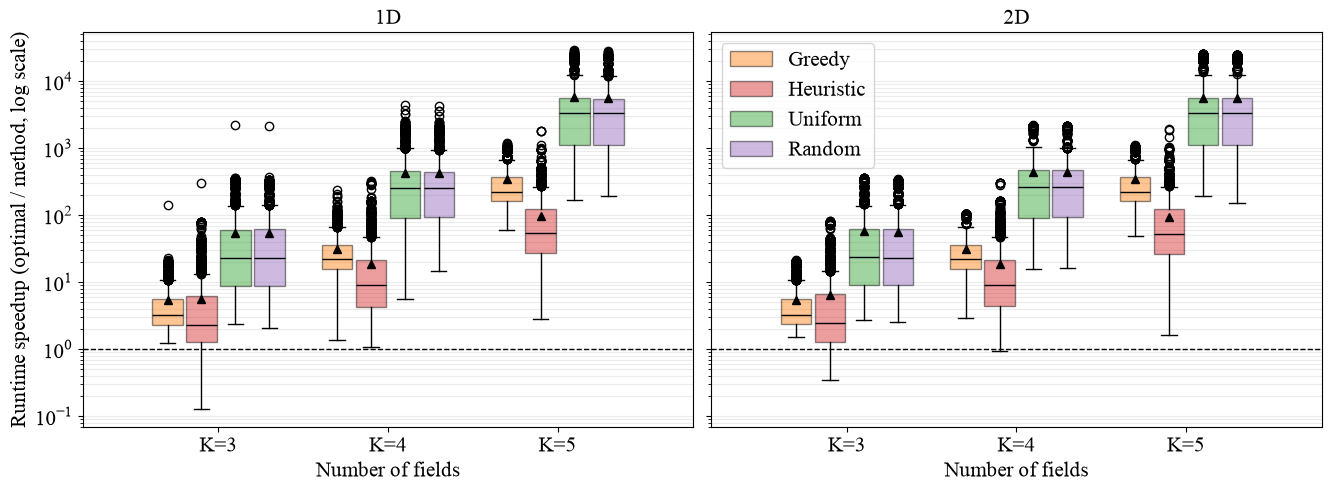

## Error gap by field family

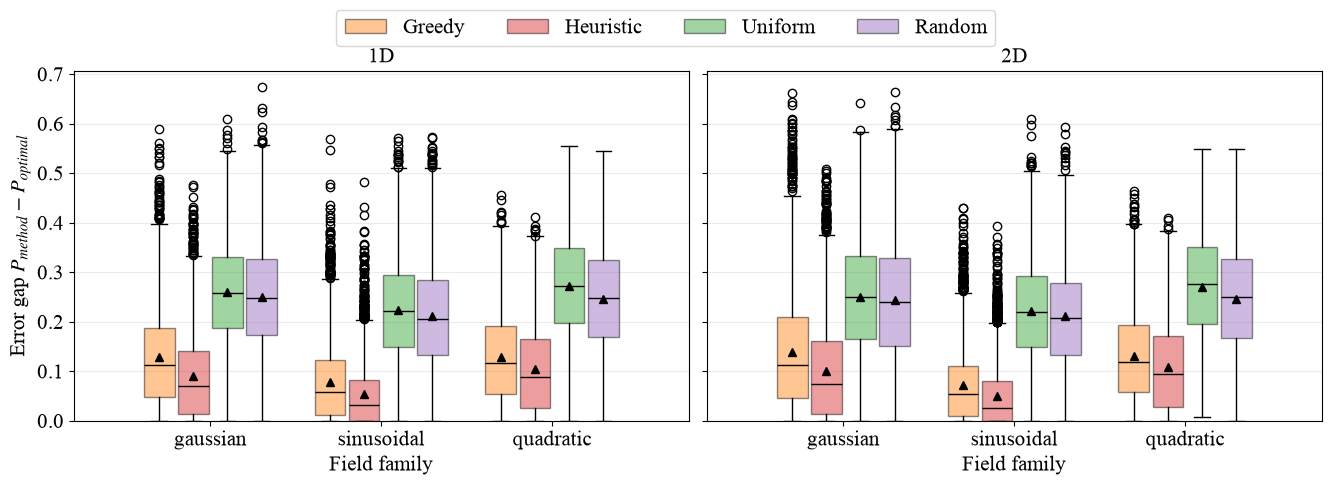

In [9]:
# Close old figures, then reload and apply the shared style.
plt.close("all")
import plot_style
plot_style = importlib.reload(plot_style)
plot_style.configure_plot_style()
# Reload plotting code so an open kernel does not reuse older functions.
comparison_analysis = importlib.reload(comparison_analysis)
# Load saved records when the expensive run cell was intentionally skipped.
if "records_by_dataset" not in globals():
    records_by_dataset = {
        dataset: comparison_analysis.load_paired_results(
            dataset, results_root=RESULTS_ROOT, run_scope=RUN_SCOPE
        )
        for dataset in DATASETS
    }
# Create the four selected figures and save PNG and PDF copies.
for title, figure in comparison_analysis.make_combined_comparison_plots(
    records_by_dataset,  # Paired results for both dimensions.
    results_root=RESULTS_ROOT,  # Base directory for comparison results.
    run_scope=RUN_SCOPE,  # Keeps test and full-run summaries separate.
):
    display(Markdown(f"## {title}"))
    display(figure)
    # Close the Python figure after displaying it to release memory.
    plt.close(figure)

## Saved files

The notebook saves detailed tables separately by dimension and puts the side-by-side figures in one combined folder:

```text
results/algorithm_comparison_compact/
├── compact_benchmark_1d_results_<test|full>/tables/
├── compact_benchmark_2d_results_<test|full>/tables/
└── results_summary_compact_benchmark_1d_compact_benchmark_2d_<test|full>/figures/
    ├── mean_error_curves.*
    ├── runtime_speedup.*
    └── error_gap_by_field_family.*
```

Each figure is saved as a 300-dpi PNG and a vector PDF.